[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/main/curso/notebooks/T01_C_stylized_facts_es.ipynb)

> **Nota para Google Colab**: la celda siguiente instala `puremacro` y, si hace falta, descarga del repositorio público [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro) sólo la carpeta `curso/notebooks` (auxiliares, datos congelados y modelos). No pide acceso a Google Drive.

[A: Datos](T01_A_data_panels_es.ipynb) · [B: Medición y ciclo](T01_B_measurement_and_cycles_es.ipynb) · [C: Hechos estilizados](T01_C_stylized_facts_es.ipynb)

In [1]:
# Configuración del entorno: Google Colab, instalación local o Juno (iPad)
import os
import sys
from pathlib import Path

def _safe_probe(p, is_dir=None):
    """¿Existe la ruta? Sin lanzar OSError/PermissionError en el sandbox de Juno."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    !pip install -q "puremacro>=4.8.1,<5"
    if not _safe_probe(Path.cwd() / "_nbstyle.py", is_dir=False):
        # Clon parcial del repositorio público: sólo curso/notebooks, sin historia
        _repo = Path("/content/puremacro")
        if not _safe_probe(_repo, is_dir=True):
            !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/jalonso1979/puremacro.git {_repo}
        !git -C {_repo} sparse-checkout set curso/notebooks 2>&1 | tail -n 2
        os.chdir(_repo / "curso/notebooks")

# Carpeta con los auxiliares del curso (_nbstyle, _datos) en sys.path, sin salir del sandbox
_candidatos = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidatos.insert(0, Path(__file__).resolve().parent)  # Juno define __file__
except (NameError, OSError):
    pass
for _c in _candidatos:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

# Gráficas en línea y estilo del curso
%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

# Módulo 1C — Hechos estilizados de largo y corto plazo

**Curso complementario · puremacro**

¿Qué regularidades debe explicar un modelo macroeconómico y cuáles sobreviven a cambios de muestra y medición? A construyó los paneles; B estableció medición y conjuntos de información. Empezamos por **crecimiento, capital y participaciones factoriales** y después estudiamos **fluctuaciones, comovimiento y anatomía de recesiones**.

### Objetivos de aprendizaje
1. Describir crecimiento y convergencia internacionales sin confundir asociación entre países con causalidad.
2. Evaluar regularidades de Kaldor sobre capital/producto y participación laboral con datos de fuentes observadas, unidades y cobertura explícitas.
3. Estimar volatilidad relativa, comovimiento, persistencia y concentración espectral en muestras trimestrales comparables.
4. Descomponer recesiones en productividad, horas por trabajador y empleo; interpretar Okun, Beveridge y Phillips como relaciones de forma reducida.
5. Convertir momentos descriptivos robustos en objetivos de un modelo, manteniendo visibles sensibilidad a la pandemia e incertidumbre de filtrado.

**Ruta:** hechos anuales de largo plazo → hechos trimestrales de corto plazo → anatomía de recesiones → objetivos del modelo. Se ejecuta con kernel nuevo y los datos congelados de A. Calculamos los resultados; ningún valor sintético sustituye observaciones faltantes de países.

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import _nbstyle
from _datos import ruta_dato
from _t01 import CONTRACT, load_panel, wide_panel, coverage, regular_block
_nbstyle.apply_style()
cols = _nbstyle.palette(6)
LANG = "es"
def tr(en, es):
    return es if LANG == "es" else en
manifest = json.loads(ruta_dato("t01_manifest.json").read_text())
print(tr("Snapshot assembly (UTC):", "Ensamblado de las copias (UTC):"), manifest["assembled_utc"])

Ensamblado de las copias (UTC): 2026-10-07T23:48:52.985790+00:00


In [3]:
a = wide_panel(load_panel("Y", variables=CONTRACT["Y"]))  # the annual series T01_A promises C
q = wide_panel(load_panel("Q", variables=CONTRACT["Q"]))  # the quarterly series T01_A promises B and C
q = q[q.gdp.notna().groupby(level="code").transform("any")]  # economies with quarterly national accounts
pwt = pd.read_csv(ruta_dato("t01_pwt110.csv.gz"))
pwt["date"] = pd.to_datetime(pwt.year.astype(str) + "-01-01")
pwt = pwt.set_index(["code", "date"]).sort_index()
a["gdp_pc"] = a.gdp_real / a.population
for var in ["gdp", "cons_hh", "inv", "capform"]:
    q[var + "_real"] = 100 * q[var] / q[var + "_defl"]
from puremacro.data import hp_filter
from puremacro.cycles import hamilton_filter
from puremacro.spectral import business_cycle_band_power
START, END = "1995-01-01", "2019-12-31"  # ← normal-times reference window; pandemic tested separately

## 1. Largo plazo: crecimiento, ingreso inicial y convergencia

Usamos PIB real por persona de cuentas nacionales del WDI para crecimiento y **PIB por persona en PPA** para comparar ingreso inicial internacional:
$$g_i=\frac{100}{T}\left[\log(Y_{i,T}/N_{i,T})-\log(Y_{i,0}/N_{i,0})\right].$$
Son tasas logarítmicas anuales medias, no promedios aritméticos de tasas porcentuales. Fijamos 1995–2019 y exigimos todas las observaciones anuales de PIB/población; conservamos la lista excluida. Regresar $g_i$ en el logaritmo del ingreso inicial en PPA describe convergencia incondicional en esa muestra. No identifica el efecto causal de enriquecer o empobrecer un país ni prueba convergencia condicional sin controles.

Muestra anual comparable: 188
Excluidos: AFG, ASM, CHI, CUB, CUW, CYM, DJI, ERI, FRO, GIB, GUM, IMN, LIE, MAF, MCO, MNE, MNP, NCL, PRK, PYF, SMR, SSD, SXM, TCA, VEN, VGB, VIR, XKX, YEM
Pendiente descriptiva sobre ingreso PPA inicial: -0.5


,growth_log_pct
count,188.00
mean,2.25
std,1.85
min,-1.80
10%,0.27
50%,1.84
90%,4.75
max,9.49


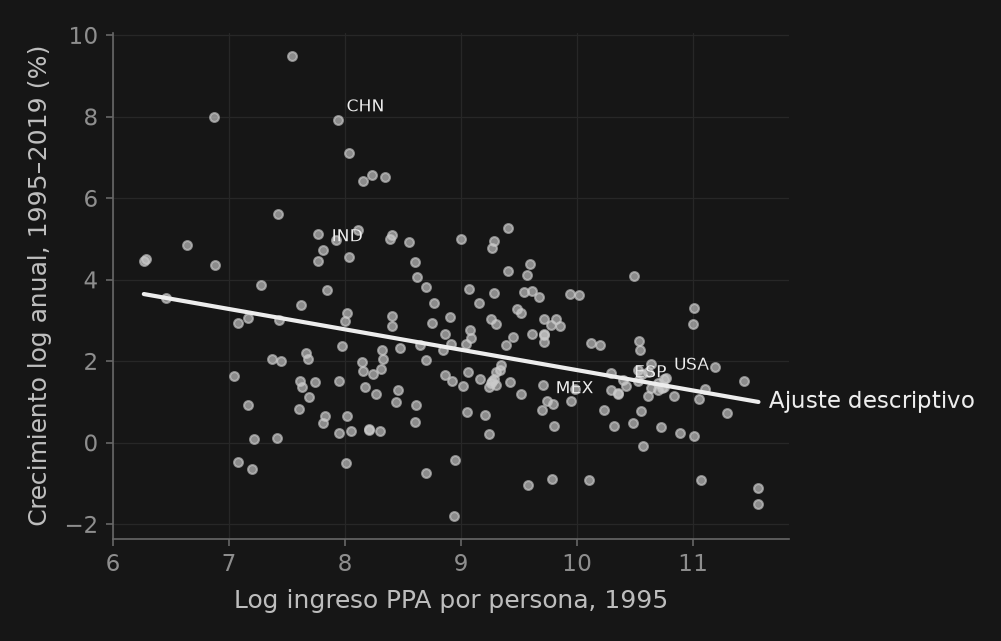

In [4]:
rows, excluded = [], []
for country, frame in a.groupby(level="code"):
    d = frame.droplevel("code")
    block = regular_block(d, ["gdp_pc"], freq="Y", start=START, end=END, min_obs=25)
    ppp0 = d.gdp_pc_ppp.get(pd.Timestamp(START), np.nan)
    if block is None or not np.isfinite(ppp0) or ppp0 <= 0:
        excluded.append(country); continue
    years = block.index[-1].year-block.index[0].year
    if not (block.gdp_pc > 0).all():
        excluded.append(country); continue
    growth = 100*np.log(block.gdp_pc.iloc[-1]/block.gdp_pc.iloc[0])/years
    rows.append({"code":country,"initial_ppp":ppp0,"growth_log_pct":growth,"n_years":len(block)})
growth_facts=pd.DataFrame(rows).set_index("code")
X=np.column_stack([np.ones(len(growth_facts)),np.log(growth_facts.initial_ppp)])
beta=np.linalg.lstsq(X,growth_facts.growth_log_pct,rcond=None)[0]
print(tr("Comparable annual sample:", "Muestra anual comparable:"),len(growth_facts))
print(tr("Excluded:", "Excluidos:"),", ".join(excluded))
print(tr("Descriptive slope on initial log PPP income:", "Pendiente descriptiva sobre ingreso PPA inicial:"),round(beta[1],3))
display(growth_facts.growth_log_pct.describe(percentiles=[.1,.5,.9]).round(2).to_frame())
fig, ax=_nbstyle.figura(1,1)
ax.scatter(np.log(growth_facts.initial_ppp),growth_facts.growth_log_pct,color=cols[1],s=18,alpha=.65)
xline=np.linspace(X[:,1].min(),X[:,1].max(),100)
ax.plot(xline,beta[0]+beta[1]*xline,color=cols[0],label=tr("Descriptive fit", "Ajuste descriptivo"))
for c in ["MEX","USA","CHN","IND","ESP"]:
    if c in growth_facts.index:
        ax.annotate(c,(np.log(growth_facts.loc[c,"initial_ppp"]),growth_facts.loc[c,"growth_log_pct"]),xytext=(4,4),textcoords="offset points",fontsize=8)
ax.set_xlabel(tr("Log PPP income per person, 1995", "Log ingreso PPA por persona, 1995"))
ax.set_ylabel(tr("Annual log growth, 1995–2019 (%)", "Crecimiento log anual, 1995–2019 (%)"))
_nbstyle.etiquetar(ax);plt.show()

**Leer la figura.** Empezamos por la dispersión del crecimiento y los países excluidos por la ventana fija. La pendiente es un rasgo descriptivo, no una ley universal de convergencia. Nuevas PPA y revisiones del PIB pueden cambiar la figura aun manteniendo fechas. El siguiente ejercicio distingue patrones temporales dentro del país y un corte transversal de niveles.

## 2. Los hechos de Kaldor son hipótesis sobre trayectorias

Capital/producto y participaciones factoriales aproximadamente estables, junto con producto creciente por trabajador, motivan crecimiento balanceado. **No** implican un mismo $K/Y$ ni una participación laboral idéntica en todos los países.

Usamos `cn/cgdpo` de PWT a PPA corrientes para el corte de 2019 y `rnna/rgdpna` a precios nacionales constantes para el cambio dentro de un país. Son stocks divididos por producto anual (**años**); `csh_i` es inversión/producto y `rkna` un índice de servicios del capital. La participación laboral de PWT incorpora supuestos de estimación e imputación de la fuente. No sustituimos faltantes por cifras representativas.

Fuente: Feenstra, Inklaar y Timmer (2015), *The Next Generation of the Penn World Table*, [PWT 11.0](https://www.rug.nl/ggdc/productivity/pwt/), [DOI](https://doi.org/10.34894/FABVLR).

,ky_ppp,labsh
count,180.00,140.00
mean,4.46,0.50
std,2.21,0.12
min,0.64,0.08
10%,2.18,0.33
50%,4.19,0.52
90%,6.74,0.64
max,14.69,0.75


,n,ky_annual_log_change,labour_share_change_pp,output_worker_annual_log_growth
count,139.0,139.00,139.00,139.00
mean,25.0,0.19,-2.56,1.90
std,0.0,1.87,8.32,1.87
min,25.0,-7.12,-35.65,-4.99
10%,25.0,-2.13,-14.15,0.01
50%,25.0,0.18,-0.91,1.77
90%,25.0,2.52,6.59,4.43
max,25.0,7.42,16.50,8.11


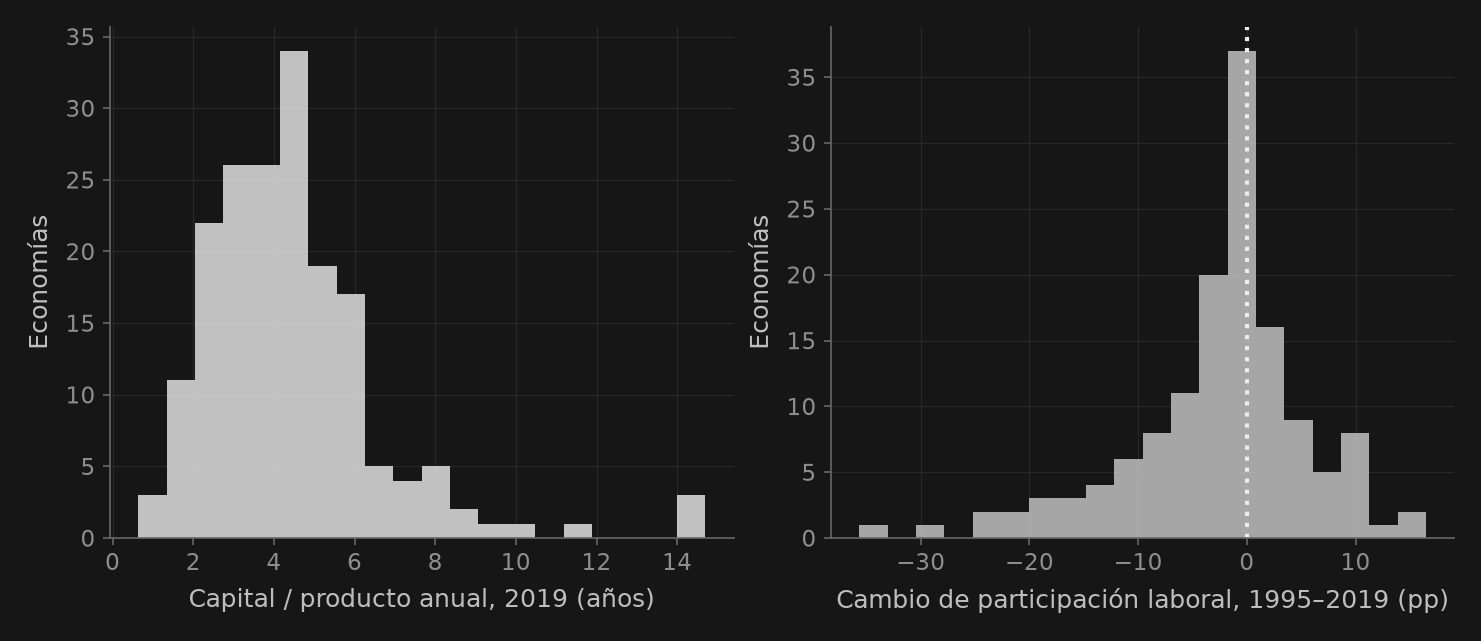

In [5]:
pwt["ky_national"] = pwt.rnna/pwt.rgdpna
pwt["ky_ppp"] = pwt.cn/pwt.cgdpo
pwt["output_per_worker"] = pwt.rgdpna/pwt.emp
cross = pwt.xs(pd.Timestamp("2019-01-01"), level="date")[["ky_ppp","labsh"]]
rows=[]
for c,d in pwt.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["ky_national","labsh","output_per_worker"],freq="Y",start=START,end=END,min_obs=25)
    if b is None or (b[["ky_national","output_per_worker"]] <= 0).any().any():
        continue
    rows.append({"code":c,"n":len(b),"ky_annual_log_change":100*np.log(b.ky_national.iloc[-1]/b.ky_national.iloc[0])/24,
                 "labour_share_change_pp":100*(b.labsh.iloc[-1]-b.labsh.iloc[0]),
                 "output_worker_annual_log_growth":100*np.log(b.output_per_worker.iloc[-1]/b.output_per_worker.iloc[0])/24})
kaldor=pd.DataFrame(rows).set_index("code")
display(cross.describe(percentiles=[.1,.5,.9]).round(2))
display(kaldor.describe(percentiles=[.1,.5,.9]).round(2))
fig, axes=_nbstyle.figura(1,2)
axes[0].hist(cross.ky_ppp.dropna(),bins=20,color=cols[0],alpha=.8)
axes[0].set_xlabel(tr("Capital / annual output, 2019 (years)","Capital / producto anual, 2019 (años)"))
axes[1].hist(kaldor.labour_share_change_pp,bins=20,color=cols[1],alpha=.8)
axes[1].axvline(0,color=cols[0],ls=":")
axes[1].set_xlabel(tr("Labour-share change, 1995–2019 (pp)","Cambio de participación laboral, 1995–2019 (pp)"))
for ax in axes:ax.set_ylabel(tr("Economies", "Economías"))
plt.show()

### 2.1 Por qué la participación laboral depende de a quién contamos

El cociente bruto de cuentas nacionales es remuneración de asalariados sobre valor añadido. Una corrección tipo Gollin imputa a los trabajadores por cuenta propia la remuneración laboral media de los asalariados:
$$s_L^{raw}=\frac{W_E}{VA},\qquad s_L^{adj}=s_L^{raw}\frac{E}{E_E}.$$
Es un supuesto sobre ingresos laborales, no una identidad contable. Usamos el mismo país-trimestre para remuneración, valor añadido y empleo. Cifras mayores que uno requieren revisar definiciones, no recortar silenciosamente. El complemento conserva el ajuste por empleo informal y la intersección entre informalidad y cuenta propia.

,first,last,n,raw_pct,adjusted_pct,quarters_above_one
code,,,,,,
MEX,2008Q1,2019Q4,48,26.67,39.64,0
GRC,1995Q1,2019Q4,100,38.23,58.40,0
ROU,1995Q1,2019Q4,100,39.79,61.18,0
SRB,1995Q1,2019Q4,100,40.20,65.99,0
BGR,1995Q1,2019Q4,100,41.51,56.65,0
IRL,1995Q1,2019Q4,100,42.41,51.35,0
ITA,1995Q1,2019Q4,100,42.92,58.98,0
SVK,1995Q1,2019Q4,100,43.28,49.60,0
POL,1995Q1,2019Q4,100,44.26,58.79,0


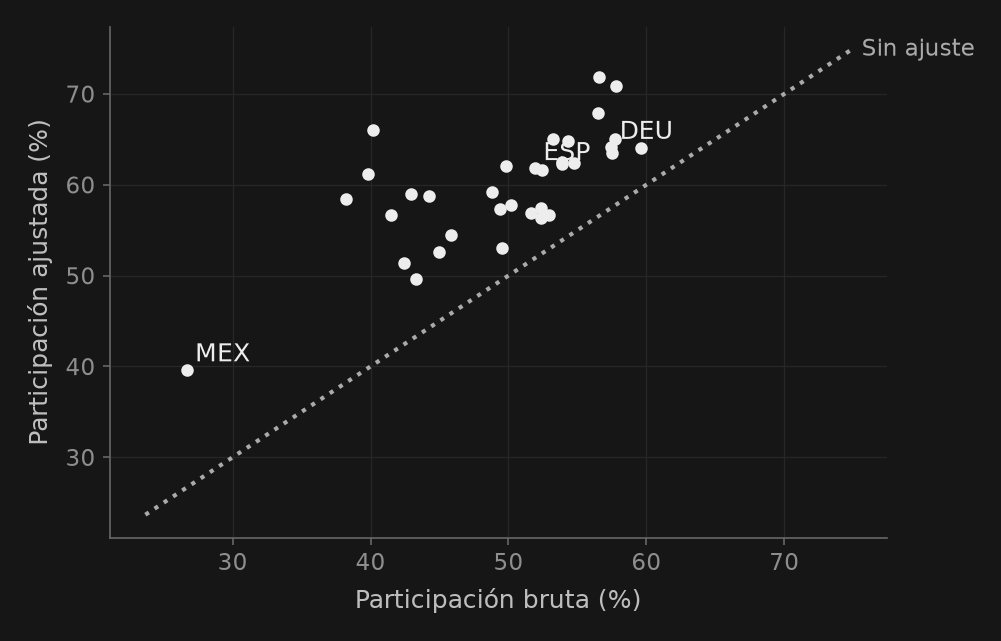

In [6]:
rows=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["comp_emp","va_total","emp","emp_employees"],start=START,end=END,min_obs=40)
    if b is None or (b[["va_total","emp_employees"]]<=0).any().any():continue
    raw=b.comp_emp/b.va_total
    adjusted=raw*b.emp/b.emp_employees
    rows.append({"code":c,"first":b.index.min().to_period("Q"),"last":b.index.max().to_period("Q"),
                 "n":len(b),"raw_pct":100*raw.mean(),"adjusted_pct":100*adjusted.mean(),
                 "quarters_above_one":int((adjusted>1).sum())})
shares=pd.DataFrame(rows).set_index("code")
display(shares.sort_values("raw_pct").round({col:2 for col in shares.sort_values("raw_pct").select_dtypes("number")}))
fig,ax=_nbstyle.figura(1,1)
ax.scatter(shares.raw_pct,shares.adjusted_pct,color=cols[0],s=25)
limits=[min(shares.raw_pct.min(),shares.adjusted_pct.min())-3,max(shares.raw_pct.max(),shares.adjusted_pct.max())+3]
ax.plot(limits,limits,color=cols[2],ls=":",label=tr("No adjustment", "Sin ajuste"))
for c in ["MEX","ESP","DEU","CHL"]:
    if c in shares.index:ax.annotate(c,(shares.loc[c,"raw_pct"],shares.loc[c,"adjusted_pct"]),xytext=(4,4),textcoords="offset points")
ax.set_xlabel(tr("Raw labour share (%)","Participación bruta (%)"))
ax.set_ylabel(tr("Adjusted labour share (%)","Participación ajustada (%)"))
_nbstyle.etiquetar(ax);plt.show()

### 2.2 Precios relativos de inversión: equipo no es construcción

$P_{eq}/P_C$ puede seguir una tendencia distinta de $P_{st}/P_C$. Calculamos cambios logarítmicos anualizados dentro de cada país y muestra común, no cocientes internacionales de niveles de deflactores con bases arbitrarias. Aquí el deflactor de consumo incluye duraderos; el complemento los separa y compara su precio directamente con equipo de inversión.

In [7]:
prices=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["inv_equip_defl","inv_struct_defl","cons_hh_defl"],start=START,end=END,min_obs=40)
    if b is None or (b<=0).any().any():continue
    relative=b[["inv_equip_defl","inv_struct_defl"]].div(b.cons_hh_defl,axis=0)
    trend=400*np.log(relative).diff().mean()
    prices.append({"code":c,"first":b.index.min().to_period("Q"),"last":b.index.max().to_period("Q"),"n":len(b),
                   "equipment_relative_price_growth":trend.inv_equip_defl,
                   "structures_relative_price_growth":trend.inv_struct_defl})
price_facts=pd.DataFrame(prices).set_index("code")
display(price_facts.round({col:2 for col in price_facts.select_dtypes("number")}))

,first,last,n,equipment_relative_price_growth,structures_relative_price_growth
code,,,,,
AUS,1995Q1,2019Q4,100,-3.53,0.70
AUT,1995Q1,2019Q4,100,-0.78,0.65
BGR,1996Q1,2019Q4,96,1.57,5.56
BIH,2000Q1,2019Q4,80,-2.89,0.61
CAN,1995Q1,2019Q4,100,-2.13,1.50
CHL,1996Q1,2019Q4,96,-2.84,-0.24
CRI,1995Q1,2019Q4,100,-0.91,-0.07
CYP,1996Q1,2010Q4,60,-0.99,0.91
CZE,1995Q1,2019Q4,100,-3.14,1.12


## 3. Corto plazo: definir el momento antes de calcularlo

Para cada pareja país-variable retenemos el mayor tramo **contiguo y común** de 1995–2019 (al menos 60 trimestres). Filtramos ambas series en esas mismas observaciones. Al comparar HP, Hamilton y primeras diferencias, evaluamos todos los métodos en sus fechas válidas comunes. Evitamos dar a un filtro más historia sin pandemia que a otro.

Para una variable transformada $x$ y producto $y$, informamos
$$\frac{\sigma(x)}{\sigma(y)},\qquad \operatorname{corr}(x,y),\qquad \operatorname{corr}(x_t,x_{t-1}).$$
Los momentos del crecimiento siguen siendo momentos del crecimiento: son contraste de robustez, no otra definición de brecha. El consumo es de hogares e incluye duraderos; `inv` es formación bruta de capital fijo. La extensión laboral utiliza horas totales, empleo, productividad $Y/H$ y horas por trabajador $H/E$, cada uno con su muestra informada.

In [8]:
q["productivity"] = q.gdp_real/q.hours
q["hours_per_worker"] = q.hours/q.emp
VARIABLES={"consumption":"cons_hh_real","investment":"inv_real","hours":"hours",
           "employment":"emp","productivity":"productivity","hours_per_worker":"hours_per_worker"}

def transformations(s):
    return pd.DataFrame({"HP":np.asarray(hp_filter(s,lamb=1600)[0]),
                         "Hamilton":np.asarray(hamilton_filter(s,h=8,p=4)[0]),
                         "growth":s.diff().to_numpy()},index=s.index)

rows=[]
for c,d in q.groupby(level="code"):
    for label,var in VARIABLES.items():
        b=regular_block(d.droplevel("code"),["gdp_real",var],start=START,end=END,min_obs=60)
        if b is None or (b<=0).any().any():continue
        y=transformations(100*np.log(b.gdp_real))
        x=transformations(100*np.log(b[var]))
        valid=y.notna().all(axis=1)&x.notna().all(axis=1)
        for method in y.columns:
            yy,xx=y.loc[valid,method],x.loc[valid,method]
            rows.append({"code":c,"variable":label,"method":method,
                         "input_first":b.index[0].to_period("Q"),"input_last":b.index[-1].to_period("Q"),
                         "n_input":len(b),"n":len(yy),"sd_ratio":xx.std()/yy.std(),
                         "corr_y":xx.corr(yy),"rho1":xx.autocorr()})
moments=pd.DataFrame(rows)
display(moments.groupby(["variable","method"]).agg(countries=("code","nunique"),
    median_sd_ratio=("sd_ratio","median"),median_corr_y=("corr_y","median"),median_rho1=("rho1","median")).round(2))
# Every comparison across methods really uses the same country-pair dates.
assert moments.groupby(["code","variable"])["n"].nunique().eq(1).all()

countries  median_sd_ratio  median_corr_y  \
variable         method                                                
consumption      HP               53             1.04           0.69   
                 Hamilton         53             1.05           0.73   
                 growth           53             1.00           0.48   
employment       HP               37             0.57           0.53   
                 Hamilton         37             0.57           0.61   
                 growth           37             0.54           0.32   
hours            HP               35             0.80           0.61   
                 Hamilton         35             0.74           0.63   
                 growth           35             0.94           0.30   
hours_per_worker HP               34             0.44           0.22   
                 Hamilton         34             0.34           0.21   
                 growth           34             0.73           0.10   
investment       HP               55             3.29           0.72   
                 Hamilton         55             2.97           0.75   
                 growth           55             3.53           0.47   
productivity     HP               35             0.81           0.64   
                 Hamilton         35             0.66           0.63   
                 growth           35             1.11           0.63   

                           median_rho1  
variable         method                 
consumption      HP               0.79  
                 Hamilton         0.87  
                 growth           0.22  
employment       HP               0.89  
                 Hamilton         0.87  
                 growth           0.42  
hours            HP               0.79  
                 Hamilton         0.84  
                 growth          -0.08  
hours_per_worker HP               0.37  
                 Hamilton         0.70  
                 growth          -0.33  
investment       HP               0.77  
                 Hamilton         0.86  
                 growth          -0.01  
productivity     HP               0.60  
                 Hamilton         0.81  
                 growth          -0.18

**Leer la distribución, no sólo la mediana.** Preguntamos si inversión es más volátil que producto, si consumo es más suave y si la productividad medida es procíclica. Informamos cuántos países apoyan cada afirmación y cuántos cambian de signo o cruzan un umbral bajo otra transformación. Un «hecho estilizado» puede describir a la mayoría y fallar en una minoría relevante. Comparar medianas marginales de países diferentes no identifica una descomposición del margen laboral.

,countries,above_under_all,below_under_all,changes_verdict
variable,,,,
consumption,53,20,16,17
investment,55,55,0,0
productivity,35,33,1,1


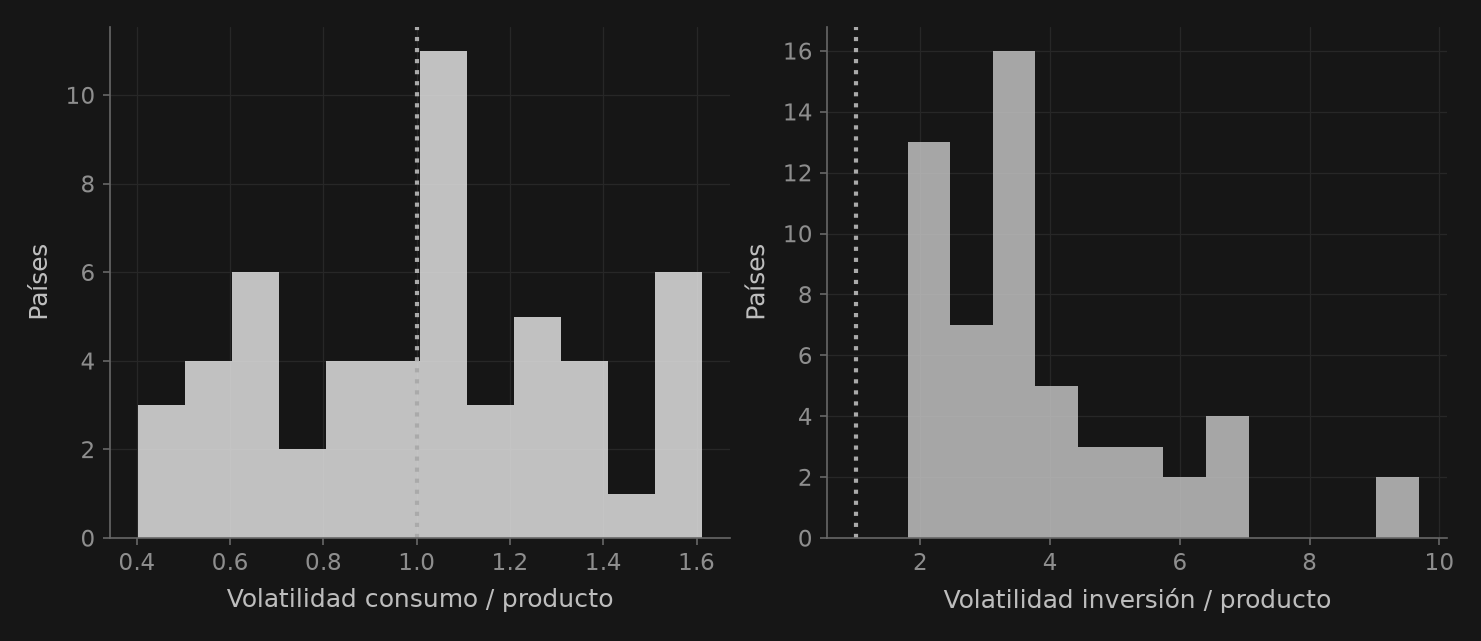

In [9]:
verdict=[]
for var in ["consumption","investment","productivity"]:
    metric="corr_y" if var=="productivity" else "sd_ratio"
    threshold=0 if var=="productivity" else 1
    table=moments.loc[moments.variable==var].pivot(index="code",columns="method",values=metric).dropna()
    positive=table.gt(threshold)
    verdict.append({"variable":var,"countries":len(table),"above_under_all":int(positive.all(axis=1).sum()),
                    "below_under_all":int((~positive).all(axis=1).sum()),
                    "changes_verdict":int(positive.nunique(axis=1).gt(1).sum())})
display(pd.DataFrame(verdict).set_index("variable"))
fig,axes=_nbstyle.figura(1,2)
for j,var in enumerate(["consumption","investment"]):
    vals=moments.query("variable == @var and method == 'HP'").sd_ratio
    axes[j].hist(vals,bins=12,color=cols[j],alpha=.8)
    axes[j].axvline(1,color=cols[2],ls=":")
    axes[j].set_xlabel(tr(var+" / output volatility", {"consumption":"Volatilidad consumo / producto","investment":"Volatilidad inversión / producto"}[var]))
    axes[j].set_ylabel(tr("Countries", "Países"))
plt.show()

### 3.1 Persistencia y banda del ciclo

La banda convencional de 6–32 trimestres corresponde a unos 1.5–8 años. Medimos la proporción de potencia del ciclo HP en esa banda con segmentos Welch comunes de 64 trimestres. Excluimos y contamos series más cortas: cambiar el segmento por país cambia la resolución frecuencial. Es concentración de una serie **filtrada**, no prueba de periodicidad determinista de la economía sin filtrar.

In [10]:
spectral_rows=[];spectral_excluded=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["gdp_real"],start=START,end=END,min_obs=64)
    if b is None or (b.gdp_real<=0).any():spectral_excluded.append(c);continue
    cycle=pd.Series(np.asarray(hp_filter(100*np.log(b.gdp_real),lamb=1600)[0]),index=b.index)
    spectral_rows.append({"code":c,"n":len(cycle),"first":b.index[0].to_period("Q"),
                          "last":b.index[-1].to_period("Q"),"sd_y":cycle.std(),"rho1_y":cycle.autocorr(),
                          "power_6_32":float(business_cycle_band_power(cycle.to_numpy(),n_seg=64))})
spectral=pd.DataFrame(spectral_rows).set_index("code")
display(spectral.round({col:3 for col in spectral.select_dtypes("number")}))
print(tr("Insufficient continuous GDP history:", "Historia continua de PIB insuficiente:"),spectral_excluded)

,n,first,last,sd_y,rho1_y,power_6_32
code,,,,,,
ALB,96,1996Q1,2019Q4,3.056,0.696,0.544
ARG,64,2004Q1,2019Q4,2.763,0.794,0.918
AUS,100,1995Q1,2019Q4,0.555,0.600,0.817
AUT,100,1995Q1,2019Q4,1.152,0.860,0.898
BEL,100,1995Q1,2019Q4,0.910,0.859,0.915
BGR,96,1996Q1,2019Q4,2.660,0.636,0.597
BIH,80,2000Q1,2019Q4,1.471,0.631,0.599
BRA,96,1996Q1,2019Q4,1.655,0.781,0.771
CAN,100,1995Q1,2019Q4,1.058,0.858,0.892


Historia continua de PIB insuficiente: ['ARM', 'CHN', 'CMR', 'COL', 'IND', 'KEN', 'KGZ', 'LSO', 'MAR', 'MDA', 'MNE', 'SAU', 'UGA']


### 3.2 Incluir la pandemia y explicar qué cambió

La base 1995–2019 define una muestra descriptiva anterior a la pandemia; no vuelve irrelevante a 2020. Comparamos volatilidad consumo/producto en los mismos países con datos completos 1995–2024. Aquí usamos **crecimientos**, para que añadir años no revise una tendencia HP en la ventana anterior. Cambia el conjunto de episodios, incluidos pandemia y recuperación; no estima causalmente sólo la pandemia.

In [11]:
sensitivity=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["gdp_real","cons_hh_real"],start="1995",end="2024",min_obs=120)
    if b is None or (b<=0).any().any():continue
    g=100*np.log(b).diff().dropna()
    old=g.loc[:"2019"]
    sensitivity.append({"code":c,"n_pre":len(old),"n_full":len(g),
                        "pre_2020":old.cons_hh_real.std()/old.gdp_real.std(),
                        "through_2024":g.cons_hh_real.std()/g.gdp_real.std()})
sensitivity=pd.DataFrame(sensitivity).set_index("code")
sensitivity["change"]=sensitivity.through_2024-sensitivity.pre_2020
display(sensitivity.sort_values("change").round(3))

,n_pre,n_full,pre_2020,through_2024,change
code,,,,,
HUN,99,119,1.517,0.928,-0.589
ESP,99,119,1.576,1.265,-0.311
PRT,99,119,1.224,1.087,-0.137
HRV,99,119,1.191,1.067,-0.124
ZAF,99,119,1.303,1.225,-0.078
GBR,99,119,1.257,1.200,-0.057
GRC,99,119,0.987,0.946,-0.041
ROU,99,119,1.589,1.559,-0.030
FRA,99,119,1.025,1.018,-0.007


## 4. Anatomía de recesiones: una identidad, tres márgenes

Usamos el mismo ámbito para producto $Y$, horas $H$ y empleo $E$:
$$Y=\frac{Y}{H}\frac{H}{E}E,\qquad \Delta\log Y=\Delta\log(Y/H)+\Delta\log(H/E)+\Delta\log E.$$
La identidad reparte un cambio observado; no identifica choques de tecnología, preferencias o política. La productividad medida puede subir al perderse empleos por composición. Comparamos **ventanas comunes fijas** (2008T1–2009T2 y 2019T4–2020T2), no los picos y valles propios de cada país. El complemento laboral conserva ese fechado y la evidencia ampliada de Okun–Beveridge–Phillips.

,code,episode,output,productivity,hours_per_worker,employment
0,AUT,GFC,-5.04,-2.39,-2.27,-0.38
1,AUT,COVID,-15.14,4.62,-15.26,-4.50
2,BEL,GFC,-3.54,-1.89,-1.97,0.32
3,BEL,COVID,-14.18,5.99,-19.02,-1.15
4,BGR,GFC,-1.65,2.46,-4.61,0.50
...,...,...,...,...,...,...
68,SVK,COVID,-10.34,9.01,-17.24,-2.10
69,SVN,GFC,-8.81,-6.92,-1.34,-0.54
70,SVN,COVID,-12.82,2.68,-13.87,-1.62
71,SWE,GFC,-6.09,-2.81,-1.15,-2.12


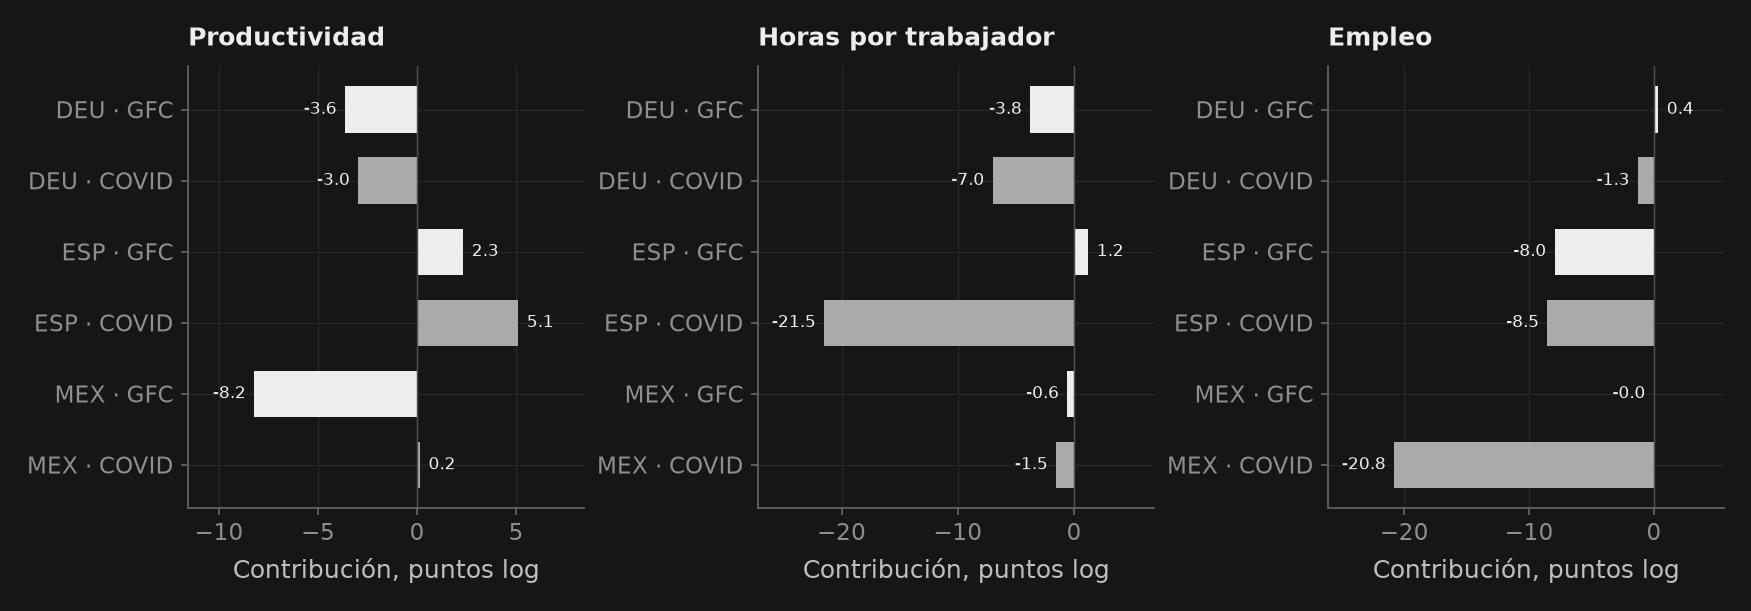

In [12]:
episodes={"GFC":("2008-01-01","2009-04-01"),"COVID":("2019-10-01","2020-04-01")}
rows=[]
for c,d in q.groupby(level="code"):
    d=d.droplevel("code")
    for episode,(start,end) in episodes.items():
        b=d.reindex(pd.to_datetime([start,end]))[["gdp_real","hours","emp"]]
        if b.isna().any().any() or (b<=0).any().any():continue
        changes=100*np.log(b.iloc[1]/b.iloc[0])
        rows.append({"code":c,"episode":episode,"output":changes.gdp_real,
                     "productivity":changes.gdp_real-changes.hours,
                     "hours_per_worker":changes.hours-changes.emp,"employment":changes.emp})
anatomy=pd.DataFrame(rows)
anatomy["residual"]=anatomy.output-anatomy.productivity-anatomy.hours_per_worker-anatomy.employment
assert anatomy.residual.abs().max()<1e-10
display(anatomy.drop(columns="residual").round(2))
fig,axes=_nbstyle.figura(1,3)
selected=["DEU","ESP","MEX"]
b=anatomy.set_index(["code","episode"]).reindex(pd.MultiIndex.from_product([selected,episodes])).dropna()
labels=[f"{c} · {e}" for c,e in b.index]
colors=[cols[0] if e=="GFC" else cols[2] for c,e in b.index]
for ax,var,title in zip(axes,["productivity","hours_per_worker","employment"],
        [tr("Productivity","Productividad"),tr("Hours per worker","Horas por trabajador"),tr("Employment","Empleo")]):
    y=np.arange(len(b))
    bars=ax.barh(y,b[var],color=colors,height=.65)
    ax.set_yticks(y,labels);ax.invert_yaxis()
    ax.bar_label(bars,fmt="%.1f",padding=4,fontsize=8)
    ax.axvline(0,color=cols[-1],lw=.7)
    ax.set_title(title)
    ax.set_xlabel(tr("Contribution, log points", "Contribución, puntos log"))
    ax.margins(x=.25)
plt.show()

### 4.1 Okun es forma reducida, no constante estructural

Relacionamos brecha de desempleo y brecha de producto en la misma muestra:
$$u_t-\tau^u_t=\alpha+\beta(y_t-\tau^y_t)+\varepsilon_t.$$
Un $\beta$ negativo resume comovimiento condicionado a definiciones, muestra y filtros. No identifica el efecto causal de intervenir en producto sobre desempleo. Beveridge describe vacantes y desempleo; Phillips, precios y holgura. Sus parámetros pueden cambiar con instituciones, expectativas, composición y política.

El [complemento laboral, §5](T01_A_business_cycle_facts_es.ipynb) conserva las tres curvas, los márgenes laborales y experimentos de recesión. El [complemento de frecuencias](T01_C_alta_frecuencia_es.ipynb) conserva flujos, emparejamiento y ajuste entre estados. Se estudian después de los hechos centrales; la identificación monetaria corresponde a los módulos empíricos posteriores.

In [13]:
okun_rows=[]
for c,d in q.groupby(level="code"):
    b=regular_block(d.droplevel("code"),["gdp_real","urate"],start=START,end=END,min_obs=60)
    if b is None or (b.gdp_real<=0).any():continue
    yg=np.asarray(hp_filter(100*np.log(b.gdp_real),lamb=1600)[0])
    ug=np.asarray(hp_filter(b.urate,lamb=1600)[0])
    X=np.column_stack([np.ones(len(b)),yg])
    fit=np.linalg.lstsq(X,ug,rcond=None)[0]
    okun_rows.append({"code":c,"first":b.index[0].to_period("Q"),"last":b.index[-1].to_period("Q"),
                      "n":len(b),"beta_descriptive":fit[1],"corr":np.corrcoef(yg,ug)[0,1]})
okun=pd.DataFrame(okun_rows).set_index("code")
display(okun.sort_values("beta_descriptive").round({col:3 for col in okun.sort_values("beta_descriptive").select_dtypes("number")}))
print(tr("Negative slopes / estimated countries:", "Pendientes negativas / países estimados:"),
      int(okun.beta_descriptive.lt(0).sum()), "/",len(okun))

,first,last,n,beta_descriptive,corr
code,,,,,
ESP,1995Q1,2019Q4,100,-0.912,-0.895
USA,1995Q1,2019Q4,100,-0.585,-0.864
BGR,2000Q1,2019Q4,80,-0.517,-0.588
GRC,1998Q2,2019Q4,87,-0.499,-0.801
PRT,1995Q1,2019Q4,100,-0.497,-0.725
POL,1997Q1,2019Q4,92,-0.495,-0.462
LTU,1998Q1,2019Q4,88,-0.477,-0.876
EST,1997Q1,2019Q4,92,-0.400,-0.799
LVA,1998Q2,2019Q4,87,-0.399,-0.895


Pendientes negativas / países estimados: 39 / 39


## 5. De los hechos a los objetivos del modelo

| Evidencia | Qué debe explicar un modelo | Qué no establece la tabla |
|---|---|---|
| Dispersión del crecimiento y trayectorias capital/producto | Acumulación, productividad y heterogeneidad | Rendimiento causal del capital desde un corte transversal |
| Participación laboral bruta y ajustada | Ingreso laboral, cuenta propia y definiciones sectoriales | Un parámetro tecnológico común a todos los países |
| Volatilidad relativa y comovimiento | Suavización del consumo, inversión y ajuste laboral | Choques estructurales identificados |
| Descomposición de recesiones | Distintos márgenes extensivo e intensivo | Choques tecnológicos a partir de productividad medida |
| Revisiones de brechas y señales del ciclo (B) | Información imperfecta de la política | Producto potencial observado y ajeno a modelos |

Un objetivo útil tiene cinco atributos: **concepto, frecuencia, muestra, transformación y vintage**. Acompañan al número. Filtrar de modo diferente modelo y datos, o calibrar con un país seleccionado y describirlo como global, cambia el ejercicio.

## 6. Tu turno

1. **Largo plazo:** compara dispersión de $K/Y$ entre países en 2019 con cambios dentro de países en 1995–2019. ¿Qué versión de «capital/producto constante» estudia cada una?
2. **Corto plazo:** elige un país donde volatilidad consumo/producto cruce uno entre transformaciones. Fija las fechas comunes y explica qué cambia.
3. **Medición:** compara participación laboral PWT con las versiones QNA bruta y ajustada. No atribuyas diferencias a una causa antes de emparejar denominadores, sectores, cuenta propia y fechas.
4. **Recesión:** sustituye la ventana fija de crisis financiera por picos y valles propios usando el complemento de fechado. Informa dónde cambia la interpretación empleo/productividad.
5. **Disciplina del modelo:** elige tres momentos robustos y escribe una tabla con los cinco atributos. Reserva causalidad y política para el módulo posterior de identificación.

### Soluciones (esquema)
Igualdad entre países y estabilidad temporal son restricciones distintas. Primeras diferencias enfatizan innovaciones de crecimiento; HP y Hamilton extraen componentes distintos. PWT y QNA pueden diferir en denominador e imputación laboral. Cambiar fechas altera los extremos de la identidad de recesión, nunca su aritmética exacta. El modelo debe afrontar el mismo procedimiento de observación y filtrado que los datos.

### Explora con IA
Pide al tutor cuestionar un objetivo de calibración: exige sensibilidad y distinción explícita entre identidad contable, correlación descriptiva y supuesto identificador.

**Sigue en el curso:** crecimiento y modelos dinámicos en el módulo 2. Los cuadernos detallados de cuentas, trabajo y alta frecuencia siguen como complementos opcionales. Sus aplicaciones causales enlazan después con los módulos 3, 5 y 8.